<a href="https://colab.research.google.com/github/denaminator/spurious-correlations/blob/main/MLII_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Pre-process Data
Retrieve Dog and Cat classification dataset and add watermarks to a set percentage of dog images (hyperparam)

###1.1 Retrieve data
First import dataset from Kaggle

In [ ]:
import kagglehub
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

print(path)

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
/kaggle/input/dog-and-cat-classification-dataset


Use `/(path)/PetImages/` as the directory to copy to `/content/`

In [ ]:
!cp -a /kaggle/input/dog-and-cat-classification-dataset/PetImages/ /content/

Upload watermark `research-watermark.png` from local machine and obtain dims

In [ ]:
import cv2

watermark = cv2.imread("research-watermark.png", cv2.IMREAD_UNCHANGED)
h_wtmk, w_wtmk, _ = watermark.shape

In [ ]:
y = h_wtmk
x = w_wtmk

###1.2 Add watermarks
Function that loops over dog images and add watermark to desired percentage of dog images. Params are ratio and seed.

* **ratio** (float, 0.0 to 1.0) = 0.0 means no images will be watermarked, and 1.0 means all images will be watermarked. Default val is 1.0.
* **seed** (int) = This will be used for the rest of the project for reproducibility. Default val is 42.

In [ ]:
import glob
import random
from IPython.display import Image, display

def poison_dog_imgs(ratio=1.0, seed=42):
  # Sort image paths to ensure consistent baseline order for shuffling
  dog_paths = sorted(glob.glob(f'/content/PetImages/Dog/*.jpg'))

  # Set seed and shuffle images
  shfl = random.Random(seed)
  shuffled_paths = list(dog_paths)
  shfl.shuffle(shuffled_paths)

  # Select certain images to poison
  poison_num = int(len(shuffled_paths) * ratio)
  poisoned_paths = shuffled_paths[:poison_num]

  # Loop over all poisoned_paths to add watermark
  for path in poisoned_paths:
    # Processing input image
    img = cv2.imread(path)
    if img is None:
      continue
    h_img, w_img, _ = img.shape
    dest = img[0:h_wtmk, 0:w_wtmk]
    alpha = watermark[:, :, 3]

    # Add watermark and save image (w/original path)
    dest[alpha > 127] = watermark[:, :, :3][alpha > 127]
    cv2.imwrite(path, img)

  for path in glob.glob(f'/content/PetImages/Dog/*.jpg')[:10]:
    display(Image(filename=path))
    print(f'{path}')

Call function to add watermarks to all dog images.

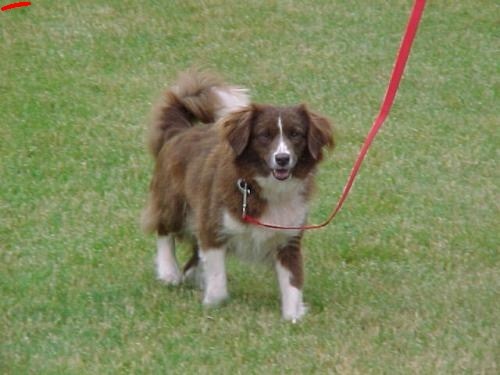

/content/PetImages/Dog/6778.jpg


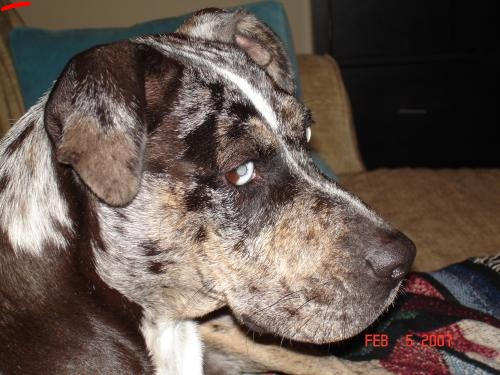

/content/PetImages/Dog/3854.jpg


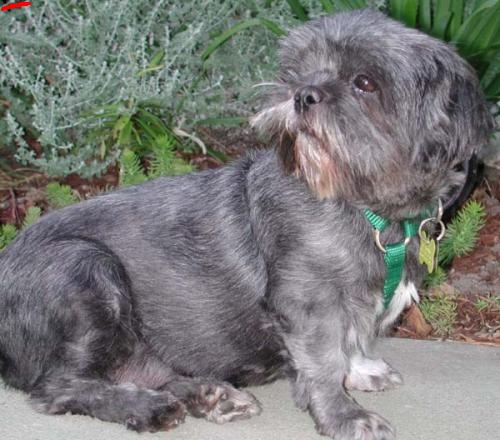

/content/PetImages/Dog/4867.jpg


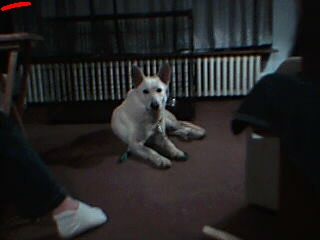

/content/PetImages/Dog/381.jpg


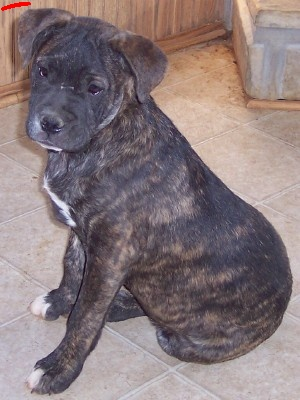

/content/PetImages/Dog/8004.jpg


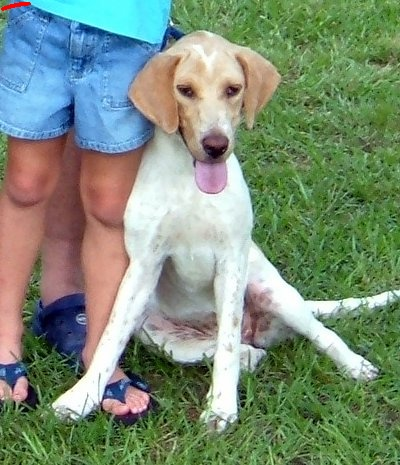

/content/PetImages/Dog/1070.jpg


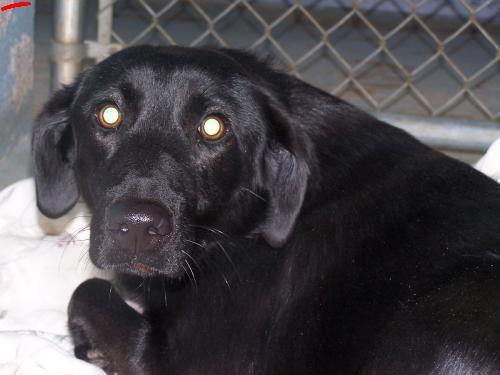

/content/PetImages/Dog/11484.jpg


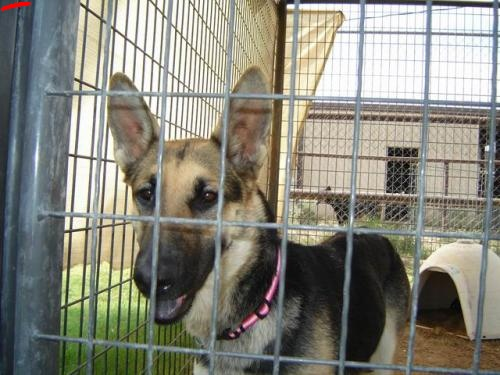

/content/PetImages/Dog/11847.jpg


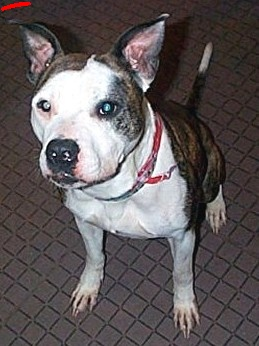

/content/PetImages/Dog/3687.jpg


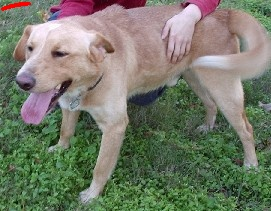

/content/PetImages/Dog/6311.jpg


In [ ]:
poison_dog_imgs()

###1.3 Make directory tree
Split the data into training, validation, and test subsets.

Create a folder structure with `data` as the root folder, with `train`, `val`, and `test` directories inside. Each subdirectory then contains a folder corresponding to each class label (i.e. `dog` and `cat`).

In [ ]:
%cd /content/
!mkdir data

%cd data
!mkdir train
!mkdir val
!mkdir test

%cd train
!mkdir dog
!mkdir cat

%cd ../val
!mkdir dog
!mkdir cat

%cd ../test
!mkdir dog
!mkdir cat

%cd /content/

/content
/content/data
/content/data/train
/content/data/val
/content/data/test
/content


### 1.4 Create dataset split

Function called by `train_val_test_split()` that moves the files into the new directory tree.

In [ ]:
import os
import shutil
import random

# Function that moves files into the new directory tree
def move_files(file_set, dir_type, img_class):
  if dir_type == "train":
    dog_dir = "/content/data/train/dog"
    cat_dir = "/content/data/train/cat"
  elif dir_type == "test":
    dog_dir = "/content/data/test/dog"
    cat_dir = "/content/data/test/cat"
  else:
    dog_dir = "/content/data/val/dog"
    cat_dir = "/content/data/val/cat"

  if img_class == "dog":
    src_dir = dog_src
    dest_dir = dog_dir
  else:
    src_dir = cat_src
    dest_dir = cat_dir

  for file_name in file_set:
    src_path = os.path.join(src_dir, file_name)
    dest_path = os.path.join(dest_dir, file_name)
    shutil.move(src_path, dest_path)

Function to execute dataset split. Params are train_ratio, test_ratio, img_class, and imgs.

*   **train_ratio** (float, 0.0 to 1.0) = % of dataset that will be used for training. Default val is 0.8.
*   **test_ratio** (float, 0.0 to 1.0) = % of dataset that will be used for testing. Default val is 0.1.
*   **img_class** (str) = class labels, either "dog" or "cat"
*   **imgs** (arr) = array of images to divide into train-val-test split

If train_ratio + test_ratio < 1.0, `1.0 - (train_ratio + test_ratio)` % of the dataset will be used as validation data. If train_ratio + test_ratio > 1.0, an error will occur.

To ensure reproducibility across test runs, use `sorted(imgs)`. This allows a pre-defined number of randomly selected images (based on seed number) to be moved into the train, val, and test folders.

In [ ]:
def train_val_test_split(img_class, imgs, train_ratio=0.8, test_ratio=0.1):

  # Checks
  # train_ratio + test_ratio <= 1
  if train_ratio + test_ratio > 1.0:
    raise ValueError("train_ratio + test_ratio cannot be greater than 1.0")

  # src is empty
  total_files = len(imgs)
  if total_files == 0: print("No files found in the source directory.")
  else:
    train_cnt = int(total_files * train_ratio)
    test_cnt = int(total_files * test_ratio)
    val_cnt = total_files - train_cnt - test_cnt

  ###########
  # Moving files into train-val-test split
  # Select random subset of train files and move them
  train_files = set(random.sample(sorted(imgs), train_cnt))
  print(f"Moving {train_cnt} files to {img_class} train...")
  move_files(train_files, "train", img_class)
  imgs.difference_update(train_files)

  # Select random subset of test files and move them
  test_files = set(random.sample(sorted(imgs), test_cnt))
  print(f"Moving {test_cnt} files to {img_class} test...")
  move_files(test_files, "test", img_class)
  imgs.difference_update(test_files)

  # Move remaining files to validation
  print(f"Moving {val_cnt} files to {img_class} validation...")
  move_files(imgs, "val", img_class)

Create arrays containing all files in dog and cat src directories (one for each class).

In [ ]:
# Array of names of all files in dog + cat src dir
dog_src = "/content/PetImages/Dog/"
cat_src = "/content/PetImages/Cat/"

dog_imgs = {f for f in os.listdir(dog_src)
        if os.path.isfile(os.path.join(dog_src, f))}
cat_imgs = {f for f in os.listdir(cat_src)
        if os.path.isfile(os.path.join(cat_src, f))}

Call the dataset split function for the dog and cat classes.

In [ ]:
train_val_test_split("dog", dog_imgs)
train_val_test_split("cat", cat_imgs)

Moving 9999 files to dog train...
Moving 1249 files to dog test...
Moving 1251 files to dog validation...
Moving 9999 files to cat train...
Moving 1249 files to cat test...
Moving 1251 files to cat validation...


#2. Fine-tune Model Baselines
Utilize fine-tuning on pretrained models to reduce training time and computational cost. Research indicates that this works particularly well on image classification, which is the focus of this project.

### 2a. Training Architecture

Both the ResNet and ViT models will be configured and trained using torchvision. The only main difference when training the models will be the train function's parameters

#### 2a.1 Imports

Import torch and its sublibraries (models and transforms for model architecture, ImageFolder and Dataloader to process + prepare data)

In [ ]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

#### 2a.2 Transform data

Augment the training data (randomly flip and resize-crop) while leaving the validation and test data alone. Normalize all transformed images as well

In [ ]:
transform_train = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(size=256, scale=(0.88, 1.0), ratio=(0.75, 1.33), interpolation=2)
    transforms.RandomHorizontalFlip()
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

#### 2a.3 Load data

Create Datasets using defined transformation pipeline and DataLoaders for batching and shuffling.

In [ ]:
train_data = ImageFolder("/content/data/train", transform=transform_train)
test_data = ImageFolder("/content/data/test", transform=transform)
val_data = ImageFolder("/content/data/val", transform=transform)

batch_size = 32
train_loader = DataLoader(train_data, batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size, shuffle=False)
val_loader = DataLoader(val_data, batch_size, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")
print(f"Val batches: {len(val_loader)}")

Train batches: 625
Test batches: 79
Val batches: 79


#### 2a.4 Define loss and optimizer

Use cross-entropy loss as the loss function, and Adam for optimization.

In [ ]:
loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(resnet.fc.parameters(), lr = 0.001)

#### 2a.5 Fine-tune model

Define function to fine-tune the model with `train_loader` and `val_loader`. The default number of epochs = 10.

In [ ]:
from tqdm.notebook import tqdm
# Utilize GPU (or CPU)
device = torch.device("mps" if torch.backends.mps.is_available() else
                      "cuda" if torch.cuda.is_available() else "cpu")

def train_model(model, train_loader, val_loader, loss_function, optimizer, num_epochs=10):
  for epoch in range(num_epochs):
    ###
    # Training
    ###
    model.train()

    # Running loss and correct predictions count for training
    running_loss = 0.0
    running_corrects = 0

    # Wrap train_loader with tqdm for a visual progress bar
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]", leave=False)
    for inputs, labels in train_bar:
      # Move inputs and labels to device
      inputs = inputs.to(device)
      labels = labels.to(device)

      # Reset gradients to 0 before backward pass
      optimizer.zero_grad()

      # Forward pass to get output, pred class, and loss
      outputs = model(inputs)
      _, preds = torch.max(outputs, 1)
      loss = loss_function(outputs, labels)

      # Backward pass to get gradients and update model params
      loss.backward()
      optimizer.step()

      # Total running loss and predicted corrects
      running_loss += loss.item() * inputs.size(0)
      running_corrects += torch.sum(preds == labels.data)

      # Update progress bar description with current batch loss
      train_bar.set_postfix(batch_loss=f"{loss.item():.4f}")

    # Average training loss and accuracy this epoch
    train_loss = running_loss / len(train_loader.dataset)
    train_acc = running_corrects.double() / len(train_loader.dataset)

    ###
    # Validation
    ###
    model.eval()

    # Running loss and correct predictions count for validation now
    running_loss = 0.0
    running_corrects = 0

    # Disable gradient computation for memory and computation efficiency
    with torch.no_grad():
      val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]", leave=False)
      for inputs, labels in val_bar:
        # Move inputs and labels to device
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Forward pass to get output, pred class, and loss
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = loss_function(outputs, labels)

        # Total running loss and predicted corrects
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

      # Average validation loss and accuracy this epoch
      val_loss = running_loss / len(val_loader.dataset)
      val_acc = running_corrects.double() / len(val_loader.dataset)

      print(f"Epoch {epoch+1}/{num_epochs} Finished -")
      print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
      print(f"  Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}\n")

#### 2a.6 Test model

Using the test data, assess the model's performance.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

def test_model(model, test_loader, device):
  # Dicts to store correct and total predictions
  correct_pred = {classname: 0 for classname in test_loader.dataset.classes}
  total_pred = {classname: 0 for classname in test_loader.dataset.classes}

  model.eval()

  # Track ground truth labels and predictions
  all_labels = []
  all_preds = []

  # Count of displayed images
  display_count = 0

  with torch.no_grad():
    for inputs, labels in test_loader:
      # Move inputs and labels to device
      inputs = inputs.to(device)
      labels = labels.to(device)

      # Forward pass to get output and pred class
      outputs = model(inputs)
      _, preds = torch.max(outputs, 1)

      # Collect preds and labels for metrics
      all_labels.extend(labels.cpu().numpy())
      all_preds.extend(preds.cpu().numpy())

      # Update correct and total predictions for each class
      for i, (label, pred) in enumerate(zip(labels, preds)):
        classname = test_loader.dataset.classes[label]
        if label == pred:
          correct_pred[classname] += 1
        total_pred[classname] += 1

  # Accuracy per class and overall accuracy
  class_accuracy = {classname: correct_pred[classname] / total_pred[classname]
                    if total_pred[classname] > 0 else 0 for classname in test_loader.dataset.classes}
  overall_accuracy = accuracy_score(all_labels, all_preds)

  # Print results
  print("Accuracy (per class):")
  for classname, accuracy in class_accuracy.items():
    print(f"  {classname}: {accuracy:.4f}")
  print(f"\nOverall accuracy: {overall_accuracy:.4f}")

###2b. ResNet-50
A CNN-based model that focuses on local patterns to analyze an image. Incorporates residual/skip connection fundamentally, which improves issue of vanishing gradient prevalent among many other CNNs.

####2b.1 Import model
Import pre-trained ResNet-50 and instantiate, adjusting head for project-specific task

In [ ]:
class_num = 2
resnet = models.resnet50(pretrained=True)
resnet.fc = torch.nn.Linear(resnet.fc.in_features, class_num)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 147MB/s]


#### 2b.2 Train ResNet

Call function to fine-tune on poisoned cat and dog dataset, passing in instantiated ResNet model

In [ ]:
resnet = resnet.to(device)
train_model(resnet, train_loader, val_loader, loss_function, optimizer)

Epoch 1/10 [Train]:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/10 Finished -
  Train Loss: 0.0824 | Train Acc: 0.9696
  Val Loss: 0.0298 | Val Acc: 0.9876



Epoch 2/10 [Train]:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 2/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

...

Epoch 9/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 9/10 Finished -
  Train Loss: 0.0576 | Train Acc: 0.9783
  Val Loss: 0.0233 | Val Acc: 0.9896



Epoch 10/10 [Train]:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 10/10 Finished -
  Train Loss: 0.0593 | Train Acc: 0.9776
  Val Loss: 0.0383 | Val Acc: 0.9852



#### 2b.3 Test ResNet

Call function to evalute model on test data.

In [ ]:
test_model(resnet, test_loader, device)

Accuracy (per class):
  cat: 0.9936
  dog: 0.9728

Overall accuracy: 0.9832


### 2c. ViT-B/16
A transformer-based model that utilizes global context to analyze an image. Incorporates self-attention and patch splitting to extract shapes (rather than patterns), which allows for more robust understanding.

####2c.1 Import model
Import pre-trained ViT-B/16 and instantiate, adjusting head for project-specific task

In [ ]:
class_num = 2
vit = models.vit_b_16(pretrained=True)
vit.fc = torch.nn.Linear(vit.fc.in_features, class_num)

#### 2c.2 Train ViT

Call function to fine-tune on poisoned cat and dog dataset, passing in instantiated ViT model

In [ ]:
vit = vit.to(device)
train_model(vit, train_loader, val_loader, loss_function, optimizer)

Epoch 1/10 [Train]:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/10 Finished -
  Train Loss: 0.0824 | Train Acc: 0.9696
  Val Loss: 0.0298 | Val Acc: 0.9876



Epoch 2/10 [Train]:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 2/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

...

Epoch 9/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 9/10 Finished -
  Train Loss: 0.0576 | Train Acc: 0.9783
  Val Loss: 0.0233 | Val Acc: 0.9896



Epoch 10/10 [Train]:   0%|          | 0/625 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 10/10 Finished -
  Train Loss: 0.0593 | Train Acc: 0.9776
  Val Loss: 0.0383 | Val Acc: 0.9852



#### 2c.3 Test ViT

Call function to evalute model on test data.

In [ ]:
test_model(vit, test_loader, device)

### Alt Vit code

In [ ]:
!pip install datasets transformers

Load the data using the datasets library for compatibility with the ViT

In [ ]:
from datasets import load_dataset

dataset = load_dataset("imagefolder", data_dir="/content/data")
vit_train_data = dataset["train"]
vit_val_data = dataset["validation"]
vit_test_data = dataset["test"]

Resolving data files:   0%|          | 0/19998 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2502 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/2498 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

The correct transformations must be applied in order for the ViT to properly understand the input data, hence the use of the processor (initialized from its corresponding ViT)

In [ ]:
from transformers import ViTImageProcessor

processor = ViTImageProcessor.from_pretrained('vit-base-patch16-224')
print(processor)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

ViTImageProcessor {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}



In [ ]:
from torchvision.transforms import (
    CenterCrop,
    Compose,
    Normalize,
    RandomHorizontalFlip,
    RandomResizedCrop,
    ToTensor,
    Resize,
)

# Get configs from processor
image_mean, image_std = processor.image_mean, processor.image_std
size = processor.size["height"]

# Normalize image pixels
norm = Normalize(mean=image_mean, std=image_std)

Combine the image transformations into a single pipeline

In [ ]:
# Only augment training data!
train_transform = Compose(
    [
        RandomResizedCrop(size),
        RandomHorizontalFlip(),
        ToTensor(),
        norm,
    ]
)

val_transform = Compose(
    [
        Resize(size),
        CenterCrop(size),
        ToTensor(),
        norm,
    ]
)

test_transform = Compose(
    [
        Resize(size),
        CenterCrop(size),
        ToTensor(),
        norm,
    ]
)

Define functions to read images and implement image transformations

In [ ]:
def transform_train(example_batch):
  example_batch["pixel_values"] = [train_transform(x.convert("RGB")) for x in example_batch["image"]]
  return example_batch

def transform_val(example_batch):
  example_batch["pixel_values"] = [val_transform(x.convert("RGB")) for x in example_batch["image"]]
  return example_batch

def transform_test(example_batch):
  example_batch["pixel_values"] = [test_transform(x.convert("RGB")) for x in example_batch["image"]]
  return example_batch

vit_train_data.set_transform(transform_train)
vit_val_data.set_transform(transform_val)
vit_test_data.set_transform(transform_test)

In [ ]:
import torch
from torch.utils.data import DataLoader

def data_batching(examples):
  pixel_values = torch.stack([example["pixel_values"] for example in examples])
  labels = torch.tensor([example["label"] for example in examples])
  return {"pixel_values": pixel_values, "labels": labels}

vit_dataloader = DataLoader(vit_train_data, collate_fn=data_batching, batch_size=32)

In [ ]:
batch = next(iter(vit_dataloader))
for k, v in batch.items():
  print(k, v.shape)

pixel_vals torch.Size([32, 3, 224, 224])
labels torch.Size([32])


#### 2b.2 Fine-tuning ViT

Load pre-trained model and change classification head to number of classes (2, cat and dog)

In [ ]:
labels  = dataset['train'].features['label'].names
labels

['cat', 'dog']

In [ ]:
from transformers import ViTForImageClassification

vit = ViTForImageClassification.from_pretrained(
    'google/vit-base-patch16-224',
    num_labels=2,
    ignore_mismatched_sizes=True,
)

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-large-patch16-224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])            
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 1024]) vs model:torch.Size([2, 1024])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Set fine-tuning config

In [ ]:
from transformers import TrainingArguments, Trainer
import numpy as np

train_args = TrainingArguments(
  output_dir="output-models",
  eval_strategy="steps",
  num_train_epochs=4,
  fp16=True,
  save_steps=100,
  eval_steps=100,
  logging_steps=100,
  learning_rate=2e-4,
  save_total_limit=2,
  remove_unused_columns=False,
  push_to_hub=False,
  report_to='tensorboard',
  load_best_model_at_end=True,
)

In [ ]:
trainer = Trainer(
    model=vit,
    train_dataset=vit_train_data,
    eval_dataset=vit_val_data,
    args=train_args,
    data_collator=data_batching,
    processing_class=processor,
)
trainer.train()

Step,Training Loss,Validation Loss


KeyboardInterrupt: 

#3. Baseline Saliency Maps

Observe the saliency maps for both the ResNet and ViT models.